In [63]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [64]:
artists = pd.read_json('artists.jsonl', lines=True)
genres_to_filter = ['pop', 'trap', 'rap', 'rock', 'metal', 'hip hop']

In [65]:
def filter_genres(genre_list, regex_pattern):
    return [genre for genre in genre_list if pd.Series([genre]).str.contains(regex_pattern, regex=True).any()]


In [66]:
filtered_artists = pd.DataFrame()
filtered_genres_dict = {}
for genre in genres_to_filter:
    regex_pattern = fr'\b({genre})\b'

    artists['filtered_genres'] = artists['genres'].apply(lambda x: filter_genres(x, regex_pattern))
    one_genre = artists[artists['filtered_genres'].apply(lambda x: x != [])]
    one_genre.loc[:, 'genres'] = genre
    filtered_artists = pd.concat([filtered_artists, one_genre], ignore_index=True)

# Drop the temporary 'filtered_genres' column
filtered_artists = filtered_artists.drop(columns=['filtered_genres'])

# Display the concatenated DataFrame
print(filtered_artists)

/tmp/ipykernel_886/77786420.py:2: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  return [genre for genre in genre_list if pd.Series([genre]).str.contains(regex_pattern, regex=True).any()]
/tmp/ipykernel_886/77786420.py:2: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  return [genre for genre in genre_list if pd.Series([genre]).str.contains(regex_pattern, regex=True).any()]


                          id                name   genres
0     7jVv8c5Fj3E9VhNjxT4snq           Lil Nas X      pop
1     0xRXCcSX89eobfrshSVdyu              MEDUZA      pop
2     4f7KfxeHq9BiylGmyXepGt      Tanishk Bagchi      pop
3     56mfhUDKa1vec6rSLZV5Eg           Jawsh 685      pop
4     6m6e7D2TnV0aYMllFFwMxu  Guilherme & Benuto      pop
...                      ...                 ...      ...
2277  50co4Is1HCEo8bhOyUWKpn          Young Thug  hip hop
2278  6U3ybJ9UHNKEdsH7ktGBZ7                 JID  hip hop
2279  1qQLhymHXFPtP5U8KNKsm6          Apache 207  hip hop
2280  6qgnBH6iDM91ipVXv28OMu          KAYTRANADA  hip hop
2281  46MWeeHNVMYRIIofQBEX98                BEAM  hip hop

[2282 rows x 3 columns]


In [67]:
len([ x for x in filtered_artists['genres'] if x == 'trap'])

268

In [68]:
filtered_artists.describe()

,id,name,genres
count,2282,2282,2282
unique,1391,1391,6
top,5gCRApTajqwbnHHPbr2Fpi,Juicy J,pop
freq,4,4,919


In [69]:
tracks = pd.read_json('tracks.jsonl', lines=True)
tracks.sample()

,id,name,popularity,duration_ms,explicit,id_artist,release_date,danceability,energy,key,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
16745,5HJqpDspKDKwQpLjvkcIsD,Burnin' It Down,66,219160,0,3FfvYsEGaIb52QPXhg4DcH,2014-10-07,0.681,0.795,6,-6.652,0.049,0.305,0.000009,0.109,0.64,135.939


In [70]:
divided_songs = {}
for genre in genres_to_filter:
    genre_frame = filtered_artists[filtered_artists['genres'] == genre]
    genre_artist_ids = genre_frame['id'].tolist()
    divided_songs[genre] = tracks[tracks['id_artist'].apply(lambda x: x in genre_artist_ids)]

In [71]:
divided_songs['pop']

,id,name,popularity,duration_ms,explicit,id_artist,release_date,danceability,energy,key,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
29,1XPj5quoeV5Gd0paSUDpvm,You Send Me - Mono,61,165733,0,6hnWRPzGGKiapVX1UCdEAC,1958-02-01,0.572,0.365,4,-7.583,0.0276,0.8800,0.00000,0.1250,0.4100,96.022
45,2G0GextMwZJLkNxcSZ7ZJ3,(What A) Wonderful World - Mono,67,128787,0,6hnWRPzGGKiapVX1UCdEAC,1960-02,0.686,0.672,11,-5.523,0.0323,0.7000,0.00000,0.1350,0.8570,128.550
46,4yjz1aazw6R8ZURpGbCAkp,Bring It On Home To Me,65,165280,0,6hnWRPzGGKiapVX1UCdEAC,1960-01-01,0.482,0.569,0,-5.897,0.0328,0.6170,0.00000,0.1550,0.6090,70.843
48,0BFEyqJ9DJXS7gKg0Kj46R,You Send Me,64,165560,0,6hnWRPzGGKiapVX1UCdEAC,1960-01-01,0.553,0.291,4,-10.426,0.0301,0.8780,0.00000,0.1290,0.4070,96.217
50,5Fih0qlqrBjPIE0dFamuBr,(What A) Wonderful World,62,129293,0,6hnWRPzGGKiapVX1UCdEAC,1960-01-01,0.763,0.571,11,-10.552,0.0337,0.5290,0.00000,0.1540,0.9360,128.211
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22407,0LcNMuOiULmxJK3bdHTfDF,Missing You,65,214987,0,7gAppWoH7pcYmphCVTXkzs,2019-04-19,0.537,0.647,2,-7.370,0.0519,0.1680,0.00000,0.1080,0.5310,79.770
22408,1uviKYHZuM4uINK33F7sCt,Fix It to Break It,70,198799,0,7okSU80WTrn4LXlyXYbX3P,2020-03-27,0.493,0.461,2,-8.524,0.0456,0.8450,0.00000,0.1150,0.3500,51.414
22409,1fXmDeiCb3ABt5CzkMxp4u,Lotus Inn,63,195868,0,2jnIB6XdLvnJUeNTy5A0J2,2020-12-04,0.578,0.740,2,-5.080,0.0721,0.0119,0.00000,0.1800,0.4950,155.984
22410,27kcZEJvhkb1rzZS9gCpdA,remember the mornings,67,202355,0,7okSU80WTrn4LXlyXYbX3P,2020-11-27,0.590,0.443,0,-5.662,0.0722,0.6180,0.00000,0.1100,0.3420,149.447


## Wyliczanie współczynnika dla każdej piosenki względem sesji

Ile razy dana piosenka znalazła się w jednej sesji z innymi piosenkami zakwalifikowanymi do tej samej grupy gatunkowej.
Nie bierzemy pod uwagę piosenek przewiniętych "skip".

In [73]:
import pandas as pd
import json

filename = 'session_third1.jsonl'

# Read and clean the JSONL file
cleaned_lines = []
with open(filename, 'r', encoding='utf-8') as file:
    for line_number, line in enumerate(file, start=1):
        line = line.strip()
        if line:
            try:
                json_obj = json.loads(line)
                cleaned_lines.append(json_obj)
            except json.JSONDecodeError as e:
                print(f"Error parsing JSON at line {line_number}: {e}")
                break

# Create a DataFrame from the cleaned lines
sessions = pd.DataFrame(cleaned_lines)


In [74]:
sessions = sessions[sessions['event_type'] == 'play']


In [75]:
for genre in genres_to_filter:
    divided_songs[genre].loc[:, 'coherence'] = 0


/tmp/ipykernel_886/422349128.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  divided_songs[genre].loc[:, 'coherence'] = 0
/tmp/ipykernel_886/422349128.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  divided_songs[genre].loc[:, 'coherence'] = 0
/tmp/ipykernel_886/422349128.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/

In [76]:
# def collect_track_ids(track_id, tracks_in_session, tracks_in_session_collected: set, last_track: list):
#     if track_id in tracks_in_session and last_track[0] in tracks_in_session:
#         tracks_in_session_collected.add(track_id)
#         tracks_in_session_collected.add(last_track[0])
#     last_track.pop()
#     last_track.append(track_id)

def collect_track_ids(track_id, tracks_in_session, tracks_in_session_collected):
    if track_id in tracks_in_session:
        tracks_in_session_collected.append(track_id)

In [77]:
divided_songs['rock'].loc[:, 'name']

11                    Blue Suede Shoes
16                Blue Moon - Take 9/M
17                        Tutti Frutti
20                      Blue Christmas
26                      Jailhouse Rock
                     ...              
22349                          Ophelia
22352                  Moth Into Flame
22392    Immortals - From "Big Hero 6”
22396                  Just Imagine It
22398                     Start A Riot
Name: name, Length: 7239, dtype: object

In [78]:
sessions_ids = set(sessions['session_id'].tolist())
for session_id in sessions_ids:
    tracks_in_session = sessions[sessions['session_id'] == session_id]['track_id'].tolist()
    for genre, track_list in divided_songs.items():
        # tracks_in_session_collected = set()
        # last_track = []
        # last_track.append(track_list.iloc[0]['id'])
        # track_list['id'].apply(lambda x: collect_track_ids(x, tracks_in_session, tracks_in_session_collected, last_track))
        tracks_in_session_collected = []
        track_list['id'].apply(lambda x: collect_track_ids(x, tracks_in_session, tracks_in_session_collected))

        if len(tracks_in_session) > 1:
            for track_id in tracks_in_session_collected:
                track_list.loc[track_list['id'] == track_id, 'coherence'] += 1

In [ ]:
# divided_songs['rock']['coherence'].apply(lambda x: print(x) if x > 100 else print('', end=''))

In [80]:
numeric_features = divided_songs['pop'].select_dtypes(include=['int64', 'float64']).columns
covariance_matrix = divided_songs['pop'][numeric_features].corr()
covariance_matrix.style.background_gradient(cmap='coolwarm', axis=None, vmin=-1, vmax=1).format(precision=3)

,popularity,duration_ms,explicit,danceability,energy,key,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,coherence
popularity,1.000,-0.130,0.070,0.064,-0.060,-0.011,0.032,0.020,-0.022,-0.015,-0.060,-0.031,-0.017,0.294
duration_ms,-0.130,1.000,-0.077,-0.166,-0.066,0.007,-0.121,-0.125,0.016,0.082,0.014,-0.171,-0.025,-0.035
explicit,0.070,-0.077,1.000,0.188,0.004,0.000,0.002,0.376,-0.042,-0.030,-0.027,-0.043,0.002,0.023
danceability,0.064,-0.166,0.188,1.000,0.138,0.010,0.134,0.166,-0.170,-0.065,-0.070,0.448,-0.178,0.015
energy,-0.060,-0.066,0.004,0.138,1.000,0.019,0.737,0.119,-0.671,-0.080,0.158,0.448,0.159,-0.013
key,-0.011,0.007,0.000,0.010,0.019,1.000,0.011,0.027,-0.011,-0.002,0.002,0.033,0.009,0.013
loudness,0.032,-0.121,0.002,0.134,0.737,0.011,1.000,0.055,-0.522,-0.239,0.091,0.281,0.107,0.008
speechiness,0.020,-0.125,0.376,0.166,0.119,0.027,0.055,1.000,-0.075,-0.049,0.061,0.071,0.090,0.014
acousticness,-0.022,0.016,-0.042,-0.170,-0.671,-0.011,-0.522,-0.075,1.000,0.056,-0.045,-0.272,-0.115,-0.003
instrumentalness,-0.015,0.082,-0.030,-0.065,-0.080,-0.002,-0.239,-0.049,0.056,1.000,-0.038,-0.105,0.000,-0.009


In [81]:
from sklearn.feature_selection import mutual_info_regression
import numpy as np
# mutual_info_regression(divided_songs['rock'].loc[:, ('popularity', 'duration_ms', 'danceability',
#                                                      'energy', 'loudness', 'speechiness', 'acousticness', 'liveness',
#                                                      'valence', 'tempo')], divided_songs['rock']['coherence'])
columns = ['popularity', 'duration_ms', 'danceability', 'energy', 'loudness',
          'speechiness', 'acousticness', 'liveness', 'valence', 'tempo', 'genre']
mutual_info = pd.DataFrame(columns=columns)
for genre in genres_to_filter:
    new_data = mutual_info_regression(divided_songs[genre].loc[:, columns[:-1]], divided_songs[genre]['coherence'])
    new_data = np.append(new_data, genre)
    new_data = new_data.reshape(1, len(new_data))
    new_rows_df = pd.DataFrame(new_data, columns=mutual_info.columns, )
    mutual_info = pd.concat([mutual_info, new_rows_df], ignore_index=True)
mutual_info

,popularity,duration_ms,danceability,energy,loudness,speechiness,acousticness,liveness,valence,tempo,genre
0,0.05163296161666597,0.0029228708513855395,0.001106414154423696,0.0,0.0,0.005376849752285473,0.0,0.004778418620301927,0.0,0.0,pop
1,0.015445547047371555,0.0,0.01837967889478076,0.0,0.0,0.0,0.006634558000454316,0.0,0.0,0.0,trap
2,0.049245103619179886,0.0,0.02442092463027823,0.011350839532625834,0.014324600500223994,0.006847415552316605,0.0,0.00979078327356131,0.02898082733522145,0.0,rap
3,0.05547001937217111,0.005207362403166549,0.005540094545136931,0.0,0.0,0.0019603333908895237,0.0,0.014840236309115795,0.0,0.005367534110621186,rock
4,0.054378655735167314,0.0,0.0,0.008267003626708291,0.018340338837925962,0.010199332846843934,0.004587560380509004,0.015815546350749443,0.0,0.002598073465969186,metal
5,0.057676373093050515,0.0,0.001272667272817607,0.0,0.0023066755606553357,0.0,0.010405351526340034,0.008941575099696841,0.00989228501919115,0.010326639385246139,hip hop


## Neural Network

In [82]:
import torch, torchvision
from torchvision import transforms
import torch.nn as nn
import torch.optim as optim
import torch.functional as F
import numpy as np
import pandas as pd
import torch.utils.data as data
import seaborn as sns
import matplotlib.pyplot as plt

In [131]:
data_raw = divided_songs['pop']
data_raw = data_raw.drop(["id", 'name', 'explicit', 'id_artist', 'key', 'release_date'], axis=1)

<module 'torch.utils.data' from '/home/michal/.local/lib/python3.10/site-packages/torch/utils/data/__init__.py'>

In [132]:
train_indices = np.random.rand(len(data_raw))>0.3

In [134]:
data_raw.loc[:, :] = data_raw.loc[:, :] .astype(float)

In [135]:
train_data = torch.tensor(data_raw.values[train_indices,:-1]).float()
train_targets = torch.from_numpy(data_raw.values[train_indices,-1]).float()

valid_data = torch.from_numpy(data_raw.values[~train_indices,:-1]).float()
valid_targets = torch.from_numpy(data_raw.values[~train_indices,-1]).float()


In [136]:
train_dataset = data.TensorDataset(train_data, train_targets)
valid_dataset = data.TensorDataset(valid_data, valid_targets)

In [137]:
data_loader_train = data.DataLoader(train_dataset, batch_size=256, shuffle=True)
data_loader_valid = data.DataLoader(valid_dataset, batch_size=256, shuffle=True)

In [138]:
class RegresionModel(nn.Module):
    def __init__(self):
        super(RegresionModel, self).__init__()
        self.layer1 = nn.Linear(train_data.shape[1], 128)
        self.act_1 = nn.LeakyReLU()

        self.bn1 = nn.BatchNorm1d(128)
        self.d1 = nn.Dropout(0.4)

        self.layer2 = nn.Linear(128, 64)
        self.bn2 = nn.BatchNorm1d(64)
        self.act_2 = nn.LeakyReLU()
        self.d2 = nn.Dropout(0.4)

        self.layer3 = nn.Linear(64, 32)
        self.bn3 = nn.BatchNorm1d(32)
        self.d3 = nn.Dropout(0.4)

        self.act_3 = nn.LeakyReLU()
        self.layer4 = nn.Linear(32, 1)
    def forward(self, x):
        activation1 = self.act_1(self.layer1(x))
        activation1 = self.bn1(activation1)

        activation1 = self.d1(activation1)
        activation2 = self.act_1(self.layer2(activation1))
        activation2 = self.bn2(activation2)

        activation2 = self.d2(activation2)

        activation3 = self.act_1(self.layer3(activation2))
        activation3 = self.bn3(activation3)

        activation3 = self.d3(activation3)

        output = self.layer4(activation3)
        return output

In [139]:
device = torch.device('cpu')

In [140]:
def get_valid_loss(model, data_loader):
    criterion = nn.MSELoss()
    model.eval()
    epoch_losses = []
    model.eval()
    with torch.no_grad():
        device_cpu = torch.device('cpu')
        for x, labels in data_loader:
            x, labels = x.to(device), labels.to(device)
        output = model(x)
        output = output.to(device_cpu)
        labels = labels.to(device_cpu)
        loss = criterion(output, labels)
        epoch_losses.append(loss.item())


    return epoch_losses

In [141]:
device = torch.device('cpu')
model = RegresionModel().to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

iters = []
losses_train = []
losses_valid = []

for n in range(1000):
    epoch_losses = []
    for x, labels in iter(data_loader_train):
        x, labels = x.to(device), labels.to(device)

        model.train()
        x = x.float()
        out = model(x)
        loss = criterion(out, labels)
        loss.backward()
        epoch_losses.append(loss.item())
        optimizer.step()
        optimizer.zero_grad()

    loss_mean_train = np.array(epoch_losses).mean()
    loss_valid = get_valid_loss(model, data_loader_valid)
    iters.append(n)
    losses_train.append(loss_mean_train)
    loss_mean_valid = np.array(loss_valid).mean()
    losses_valid.append(loss_mean_valid)

    print(f"Train epoch {n} loss {loss_mean_train:.3}")
    print(f'Valid epoch {n} loss {loss_mean_valid}')

/home/michal/.local/lib/python3.10/site-packages/torch/nn/modules/loss.py:535: UserWarning: Using a target size (torch.Size([256])) that is different to the input size (torch.Size([256, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
/home/michal/.local/lib/python3.10/site-packages/torch/nn/modules/loss.py:535: UserWarning: Using a target size (torch.Size([188])) that is different to the input size (torch.Size([188, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
/home/michal/.local/lib/python3.10/site-packages/torch/nn/modules/loss.py:535: UserWarning: Using a target size (torch.Size([185])) that is different to the input size (torch.Size([185, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same

Train epoch 0 loss 2.28e+03
Valid epoch 0 loss 2391.627197265625
Train epoch 1 loss 2.27e+03
Valid epoch 1 loss 2310.742919921875
Train epoch 2 loss 2.25e+03
Valid epoch 2 loss 2217.327392578125
Train epoch 3 loss 2.22e+03
Valid epoch 3 loss 1994.701904296875
Train epoch 4 loss 2.18e+03
Valid epoch 4 loss 2073.364990234375
Train epoch 5 loss 2.12e+03
Valid epoch 5 loss 1956.731689453125
Train epoch 6 loss 2.05e+03
Valid epoch 6 loss 1824.136474609375
Train epoch 7 loss 1.97e+03
Valid epoch 7 loss 1856.7147216796875
Train epoch 8 loss 1.88e+03
Valid epoch 8 loss 2114.165771484375
Train epoch 9 loss 1.78e+03
Valid epoch 9 loss 1629.7501220703125
Train epoch 10 loss 1.67e+03
Valid epoch 10 loss 1577.53271484375
Train epoch 11 loss 1.56e+03
Valid epoch 11 loss 1218.400390625
Train epoch 12 loss 1.44e+03
Valid epoch 12 loss 1248.414306640625
Train epoch 13 loss 1.34e+03
Valid epoch 13 loss 1275.5943603515625
Train epoch 14 loss 1.22e+03
Valid epoch 14 loss 1238.0255126953125
Train epoch 15 

MSE squered: 18.98843272607242


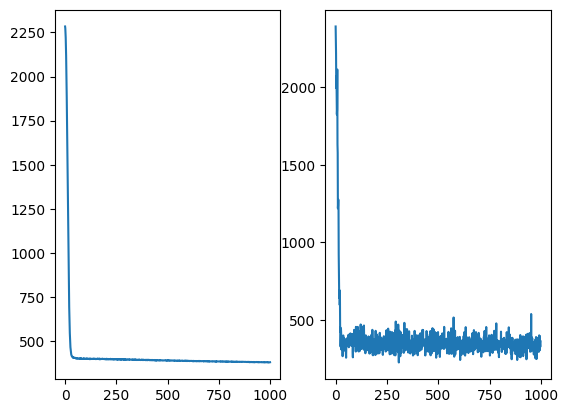

In [168]:
fig, (ax1, ax2) = plt.subplots(1, 2)
ax1.plot(iters[:], losses_train[:])
ax2.plot(iters[:], losses_valid[:])
print(f'MSE squered: {losses_valid[-1] ** (1/2)}')

## Gradient Boost

In [166]:
from numpy import mean
from numpy import std
from sklearn.datasets import make_regression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import RepeatedKFold
from matplotlib import pyplot
from sklearn.impute import SimpleImputer
# define dataset
X, y = make_regression(n_samples=1000, n_features=10, n_informative=5, random_state=1)

# evaluate the model
model = GradientBoostingRegressor()
cv = RepeatedKFold(n_splits=10, n_repeats=3, random_state=1)
model = GradientBoostingRegressor()

n_scores = cross_val_score(model, data_raw.iloc[:, :-1], data_raw.iloc[:, -1], scoring='neg_mean_squared_error', cv=cv, n_jobs=-1, error_score='raise')
print('MSE: %.3f (%.3f)' % (mean(n_scores), std(n_scores)))

MSE: -329.242 (11.825)
